# Lights, Camera, Revenue: 55 Years of Movies

**What does it take for a film to succeed, and does "good" mean the same thing as "profitable"?**

This dashboard explores **10,865 films released from 1960 to 2015**, using data from [The Movie Database (TMDb)](https://www.themoviedb.org/).
Each film has its release year, genres, director, runtime, budget and box-office revenue, along with audience **popularity** and **vote average** (a 0–10 user rating).
All dollar figures are **inflation-adjusted to 2010 dollars**. Budget and revenue are reported for about 4,750 films, and profit (revenue − budget) for about 3,800.

### Research questions
1. **Output over time:** How have the number of releases and the money they earn changed over time?
2. **Runtime:** Do longer movies draw smaller audiences, or better scores?
3. **Genres:** Which genres are the most profitable, which are the best reviewed, and has that changed by decade?
4. **Critical vs commercial success:** Do highly rated movies also make more money?

The first section gives the headline findings. The **Explore** section below it lets you test them yourself.

In [1]:
import io
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

%matplotlib inline
plt.rcParams.update({
    'figure.figsize': (10, 4.8), 'figure.dpi': 100,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titleweight': 'bold', 'axes.titlesize': 13, 'font.size': 11,
})
BLUE, ORANGE, GRAY, RED, DARK = '#2a6f97', '#e07a1f', '#c4c4c4', '#c0392b', '#333333'

movies = pd.read_csv('tmdb-movies.csv').drop_duplicates()
for col in ['budget_adj', 'revenue_adj', 'runtime']:
    movies[col] = movies[col].replace(0, np.nan)
for col in ['budget_adj', 'revenue_adj']:          # a few films report budgets/revenues of a few dollars
    movies[col] = movies[col].where(movies[col] >= 1e4)
movies['decade'] = movies['release_year'] // 10 * 10
movies['profit'] = movies['revenue_adj'] - movies['budget_adj']
movies['roi'] = (movies['revenue_adj'] / movies['budget_adj']).where(movies['budget_adj'] >= 1e5)
RUNTIME_LABELS = ['<90', '90-99', '100-109', '110-119', '120-134', '135-149', '150+']
movies['runtime_bin'] = pd.cut(movies['runtime'], bins=[0, 89, 99, 109, 119, 134, 149, 1000],
                               labels=RUNTIME_LABELS)

genres = (movies.dropna(subset=['genres'])
          .assign(genre=lambda d: d['genres'].str.split('|'))
          .explode('genre'))
genres = genres[genres['genre'] != 'TV Movie']   # only a handful of films; not meaningful
GENRE_LIST = sorted(genres['genre'].unique())
DECADES = sorted(int(x) for x in movies['decade'].unique())

rated = movies.dropna(subset=['revenue_adj']).copy()
rated['log_revenue'] = np.log10(rated['revenue_adj'])
SLOPE, INTERCEPT = np.polyfit(rated['vote_average'], rated['log_revenue'], 1)
rated['residual'] = rated['log_revenue'] - (SLOPE * rated['vote_average'] + INTERCEPT)

def films_in_genre(df, genre):
    # Keep films tagged with `genre` ('All' keeps everything).
    if genre == 'All':
        return df
    return df[df['genres'].fillna('').str.split('|').apply(lambda g: genre in g)]

def money(x, pos=None):
    if abs(x) >= 1e9:
        return f'${x/1e9:g}B'
    if abs(x) >= 1e6 or x == 0:
        return f'${x/1e6:.0f}M'
    return f'${x/1e3:g}K' if abs(x) >= 1e3 else f'${x:.0f}'

STYLE = {'description_width': 'initial'}

def chart(draw, controls):
    # Interactive chart: redraw draw(**control values) whenever a control changes.
    # draw() returns a matplotlib figure, or (figure, note) to show a line of text under it.
    # The figure is shown as PNG bytes in an Image widget, which renders reliably under Voila on Binder.
    image = widgets.Image(format='png', layout=widgets.Layout(max_width='100%', height='auto'))
    note = widgets.HTML()
    def update(_=None):
        result = draw(**{name: w.value for name, w in controls.items()})
        fig, text = result if isinstance(result, tuple) else (result, '')
        buf = io.BytesIO()
        fig.savefig(buf, format='png', bbox_inches='tight', facecolor='white')
        plt.close(fig)
        image.value = buf.getvalue()
        note.value = f'<p>{text}</p>' if text else ''
    for w in controls.values():
        w.observe(update, 'value')
    update()
    return widgets.VBox([image, note])

---
## Key insights

### 1. Twenty times more movies, but the typical movie earns less
Studios released **32 films** in this dataset in 1960 and **over 600 a year** by 2014–2015.
Over the same period the **median** film's inflation-adjusted revenue fell from well over $100M in the late 1960s and 70s to about **$30M** in the 2010s.
A few blockbusters still earn huge sums (the top 10% of films take about half of all revenue), but the typical release now brings in much less.
Part of the early peak comes from older records mostly covering hits, but the drop since 2000, when coverage is good, is real.

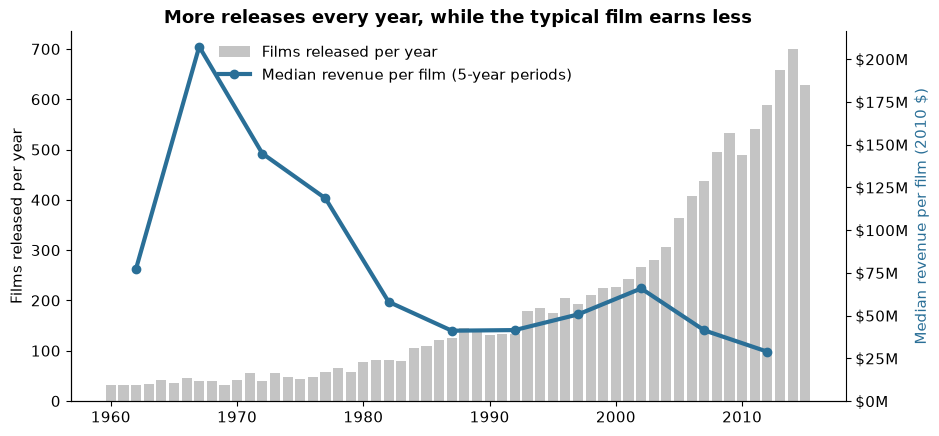

In [2]:
yearly = movies.groupby('release_year')['id'].count()
period = movies.assign(period=movies['release_year'] // 5 * 5).groupby('period')['revenue_adj'].median()
period = period.drop(2015)          # 2015 is a single year, not a 5-year period

fig, ax = plt.subplots()
ax.bar(yearly.index, yearly, color=GRAY, width=0.8, label='Films released per year')
ax.set_ylabel('Films released per year')
ax2 = ax.twinx()
ax2.plot(period.index + 2, period, color=BLUE, lw=3, marker='o', label='Median revenue per film (5-year periods)')
ax2.yaxis.set_major_formatter(money)
ax2.set_ylabel('Median revenue per film (2010 $)', color=BLUE)
ax2.spines['right'].set_visible(True)
ax2.set_ylim(0)
ax.set_title('More releases every year, while the typical film earns less')
fig.legend(loc='upper center', bbox_to_anchor=(0.45, 0.88), frameon=False)
plt.show()

### 2. Longer movies get better scores
Films under 110 minutes average about **6.0–6.1/10**. Past that, the score climbs with every bracket, up to **7.0** for films over two and a half hours. Long running times are often given to prestige projects (epics, biopics, dramas),
so the length itself may not be what earns the higher score.

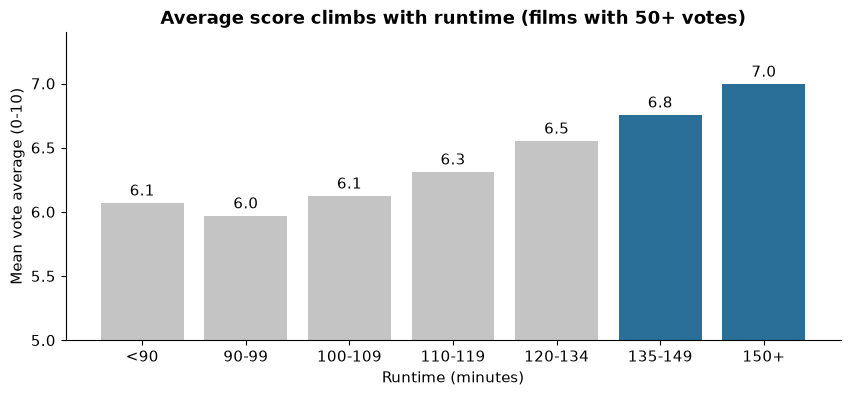

In [3]:
d = movies[movies['vote_count'] >= 50].dropna(subset=['runtime_bin'])
score = d.groupby('runtime_bin', observed=True)['vote_average'].mean()

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(score.index.astype(str), score, color=[GRAY] * (len(score) - 2) + [BLUE] * 2)
ax.bar_label(bars, fmt='%.1f', padding=3)
ax.set_ylim(5, 7.4)
ax.set_xlabel('Runtime (minutes)')
ax.set_ylabel('Mean vote average (0-10)')
ax.set_title('Average score climbs with runtime (films with 50+ votes)')
plt.show()

### 3. What audiences rate highest is not what makes the most money
Documentaries, war and history films get the **best ratings**, while adventure and family films are among the **most profitable** with middling scores.
Drama, the most common genre, rates well but has one of the lowest median profits. Animation is the rare genre that does both.
Across individual films, rating and revenue are only weakly related (**r ≈ 0.18**): *The Shawshank Redemption* is the top-rated film here (8.4)
but earned only about $42M.

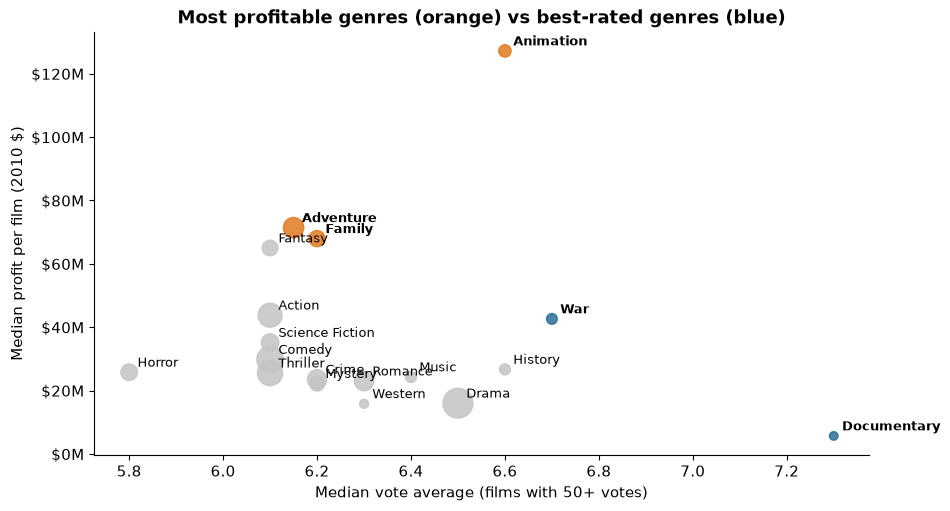

In [4]:
g = (genres.dropna(subset=['profit'])
     .groupby('genre').agg(median_profit=('profit', 'median'), n=('id', 'count')))
g['median_rating'] = genres[genres['vote_count'] >= 50].groupby('genre')['vote_average'].median()
g = g[g['n'] >= 30].dropna()

fig, ax = plt.subplots(figsize=(10, 5.5))
top_profit = g['median_profit'].nlargest(3).index
top_rating = g['median_rating'].nlargest(3).index
colors = [ORANGE if x in top_profit else BLUE if x in top_rating else GRAY for x in g.index]
ax.scatter(g['median_rating'], g['median_profit'], s=g['n'] / 4 + 30, color=colors, alpha=0.85)
for name, row in g.iterrows():
    ax.annotate(name, (row['median_rating'], row['median_profit']), xytext=(6, 4),
                textcoords='offset points', fontsize=9,
                fontweight='bold' if name in top_profit.union(top_rating) else 'normal')
ax.yaxis.set_major_formatter(money)
ax.set_xlabel('Median vote average (films with 50+ votes)')
ax.set_ylabel('Median profit per film (2010 $)')
ax.set_title('Most profitable genres (orange) vs best-rated genres (blue)')
plt.show()

---
## Explore

Each tab answers one research question. Use the controls above a chart to filter it and see whether the patterns above still hold.

In [5]:
# ---------- Q1: output over time
q1_years = widgets.IntRangeSlider(value=(1960, 2015), min=1960, max=2015, description='Years', style=STYLE,
                                  layout=widgets.Layout(width='420px'))
q1_stat = widgets.ToggleButtons(options=['Median', 'Mean'], description='Revenue per film', style=STYLE)
q1_genre = widgets.Dropdown(options=['All'] + GENRE_LIST, description='Genre', style=STYLE)

def q1_trend(years, stat, genre):
    d = films_in_genre(movies, genre)
    d = d[d['release_year'].between(*years)]
    yearly = d.groupby('release_year').agg(n=('id', 'count'), rev=('revenue_adj', stat.lower()))
    fig, ax = plt.subplots()
    ax.bar(yearly.index, yearly['n'], color=GRAY, label='Films released')
    ax.set_ylabel('Films released')
    ax2 = ax.twinx()
    ax2.plot(yearly.index, yearly['rev'], color=BLUE, lw=2, marker='o', ms=3, label=f'{stat} revenue per film')
    ax2.yaxis.set_major_formatter(money)
    ax2.set_ylabel(f'{stat} revenue per film (2010 $)', color=BLUE)
    ax2.spines['right'].set_visible(True)
    ax2.set_ylim(0)
    r = yearly['n'].corr(yearly['rev'])
    ax.set_title(f'{genre if genre != "All" else "All"} films, {years[0]}-{years[1]}: '
                 f'releases vs {stat.lower()} revenue (r = {r:.2f})')
    fig.legend(loc='upper left', bbox_to_anchor=(0.08, 0.88), frameon=False)
    return fig

q1_level = widgets.Dropdown(options=[('Year', 'release_year'), ('Decade', 'decade')], description='Group by', style=STYLE)
q1_measure = widgets.ToggleButtons(options=['Total', 'Per film'], description='Measure', style=STYLE)

def q1_extremes(level, measure):
    grouped = movies.groupby(level)['revenue_adj']
    s = grouped.sum() if measure == 'Total' else grouped.mean()
    z = (s - s.mean()) / s.std()
    colors = [RED if v > 1.5 else BLUE if v < -1.5 else GRAY for v in z]
    fig, ax = plt.subplots()
    labels = s.index.astype(str) if level == 'release_year' else [f'{x}s' for x in s.index]
    ax.bar(labels, s, color=colors)
    ax.yaxis.set_major_formatter(money)
    ax.set_ylabel(f'{measure} revenue (2010 $)')
    ax.set_title(f'{measure} box-office revenue by {"year" if level == "release_year" else "decade"}: '
                 'red = unusually high, blue = unusually low (|z| > 1.5)')
    if level == 'release_year':
        ax.set_xticks(range(0, len(s), 5))
    return fig, ('<b>Highest:</b> ' + ', '.join(map(str, s.nlargest(3).index))
                 + ' &nbsp;&nbsp; <b>Lowest:</b> ' + ', '.join(map(str, s.nsmallest(3).index)))

q1_panel = widgets.VBox([
    widgets.HTML('<h3>How have releases and revenue per film changed over time?</h3>'),
    widgets.HBox([q1_years, q1_genre]), q1_stat,
    chart(q1_trend, {'years': q1_years, 'stat': q1_stat, 'genre': q1_genre}),
    widgets.HTML('<h3>Which years or decades had unusually high or low box office?</h3>'),
    widgets.HBox([q1_level, q1_measure]),
    chart(q1_extremes, {'level': q1_level, 'measure': q1_measure}),
])

In [6]:
# ---------- Q2: runtime
q2_metric = widgets.Dropdown(options=[('Popularity', 'popularity'), ('Revenue', 'revenue_adj')],
                             description='Audience measure', style=STYLE)
q2_genre = widgets.Dropdown(options=['All'] + GENRE_LIST, description='Genre', style=STYLE)
q2_runtime = widgets.IntRangeSlider(value=(60, 200), min=40, max=240, step=5, description='Runtime (min)',
                                    style=STYLE, layout=widgets.Layout(width='420px'))

def q2_viewership(metric, genre, runtime):
    d = films_in_genre(movies, genre)
    d = d[d['runtime'].between(*runtime)].dropna(subset=['runtime', metric])
    d = d[d[metric] > 0]
    trend = d.groupby('runtime_bin', observed=True).agg(runtime=('runtime', 'median'), value=(metric, 'median'))
    fig, ax = plt.subplots()
    ax.scatter(d['runtime'], d[metric], alpha=0.2, s=10, color=BLUE)
    ax.plot(trend['runtime'], trend['value'], color=DARK, marker='o', lw=2, label='Median per runtime bracket')
    ax.set_yscale('log')
    if metric == 'revenue_adj':
        ax.yaxis.set_major_formatter(money)
    ax.set_xlabel('Runtime (minutes)')
    ax.set_ylabel(q2_metric.label + ' (log scale)')
    rho = d['runtime'].rank().corr(d[metric].rank())   # Spearman, without scipy
    ax.set_title(f'Runtime vs {q2_metric.label.lower()}, {genre} films (Spearman ρ = {rho:.2f}, n = {len(d):,})')
    ax.legend(frameon=False)
    return fig

q2_votes = widgets.IntSlider(value=50, min=10, max=1000, step=10, description='Minimum votes', style=STYLE)
q2_genre2 = widgets.Dropdown(options=['All'] + GENRE_LIST, description='Genre', style=STYLE)

def q2_score(min_votes, genre):
    d = films_in_genre(movies, genre)
    d = d[d['vote_count'] >= min_votes].dropna(subset=['runtime_bin'])
    data = [d.loc[d['runtime_bin'] == b, 'vote_average'] for b in RUNTIME_LABELS]
    keep = [i for i, x in enumerate(data) if len(x) >= 3]
    fig, ax = plt.subplots()
    ax.boxplot([data[i] for i in keep], positions=range(len(keep)), widths=0.5,
               patch_artist=True, boxprops=dict(facecolor='#dbe8f0', color=BLUE), medianprops=dict(color=DARK))
    ax.plot(range(len(keep)), [data[i].mean() for i in keep], color=ORANGE, marker='D', label='Mean')
    ax.set_xticks(range(len(keep)), [f'{RUNTIME_LABELS[i]}\n(n={len(data[i])})' for i in keep])
    ax.set_xlabel('Runtime (minutes)')
    ax.set_ylabel('Vote average (0-10)')
    rho = d['runtime'].rank().corr(d['vote_average'].rank())   # Spearman, without scipy
    ax.set_title(f'Score by runtime, {genre} films with {min_votes}+ votes (Spearman ρ = {rho:.2f})')
    ax.legend(frameon=False)
    return fig

q2_panel = widgets.VBox([
    widgets.HTML('<h3>Do longer movies draw smaller audiences?</h3>'),
    widgets.HBox([q2_metric, q2_genre]), q2_runtime,
    chart(q2_viewership, {'metric': q2_metric, 'genre': q2_genre, 'runtime': q2_runtime}),
    widgets.HTML('<h3>Do longer movies get higher scores?</h3>'),
    widgets.HBox([q2_votes, q2_genre2]),
    chart(q2_score, {'min_votes': q2_votes, 'genre': q2_genre2}),
])

In [7]:
# ---------- Q3: genres
GENRE_METRICS = {'Median profit': ('profit', 'median'), 'Median return on budget (×)': ('roi', 'median'),
                 'Median vote average': ('vote_average', 'median')}

def genre_table(metric, min_films=5):
    col, agg = GENRE_METRICS[metric]
    d = genres.dropna(subset=[col])
    if col == 'vote_average':
        d = d[d['vote_count'] >= 50]
    val = d.pivot_table(index='genre', columns='decade', values=col, aggfunc=agg)
    n = d.pivot_table(index='genre', columns='decade', values=col, aggfunc='count')
    return val.where(n >= min_films)

q3_metric = widgets.RadioButtons(options=list(GENRE_METRICS), description='Rank genres by', style=STYLE)
q3_decade = widgets.SelectionSlider(options=[(f'{x}s', x) for x in DECADES], value=2010, description='Decade',
                                    style=STYLE, layout=widgets.Layout(width='420px'))

def q3_rank(metric, decade):
    table = genre_table(metric)
    s = table[decade].dropna().sort_values()
    ranks = table.rank(ascending=False)
    fig, (ax, axh) = plt.subplots(1, 2, figsize=(13, 6), gridspec_kw={'width_ratios': [1, 1.3]})
    ax.barh(s.index, s, color=[GRAY] * max(len(s) - 3, 0) + [BLUE] * min(3, len(s)))
    if 'profit' in metric:
        ax.xaxis.set_major_formatter(money)
    ax.set_title(f'{metric} by genre, {decade}s')
    # rank heatmap across decades, selected decade outlined
    r = ranks.loc[s.index[::-1]]
    axh.imshow(r, cmap='Blues_r', aspect='auto', vmin=1, vmax=len(ranks))
    axh.set_xticks(range(len(r.columns)), [f'{c}s' for c in r.columns])
    axh.set_yticks(range(len(r.index)), r.index)
    for i in range(r.shape[0]):
        for j in range(r.shape[1]):
            if not np.isnan(r.iat[i, j]):
                axh.text(j, i, int(r.iat[i, j]), ha='center', va='center', fontsize=8,
                         color='white' if r.iat[i, j] <= len(ranks) / 2 else DARK)
    j = list(r.columns).index(decade)
    axh.add_patch(plt.Rectangle((j - 0.5, -0.5), 1, len(r), fill=False, color=ORANGE, lw=3))
    axh.set_title('Rank in each decade (1 = best; blank = under 5 films)')
    axh.spines[:].set_visible(False)
    fig.tight_layout()
    return fig

q3_votes = widgets.IntSlider(value=50, min=10, max=1000, step=10, description='Minimum votes', style=STYLE)
q3_sort = widgets.ToggleButtons(options=['Median', 'Spread (std)'], description='Sort by', style=STYLE)

def q3_spread(min_votes, sort):
    d = genres[genres['vote_count'] >= min_votes]
    stats = d.groupby('genre')['vote_average'].agg(['median', 'std', 'count'])
    stats = stats[stats['count'] >= 5]
    order = stats.sort_values('median' if sort == 'Median' else 'std').index
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.boxplot([d.loc[d['genre'] == g, 'vote_average'] for g in order], tick_labels=order, vert=False,
               patch_artist=True, boxprops=dict(facecolor='#dbe8f0', color=BLUE), medianprops=dict(color=DARK),
               flierprops=dict(markersize=3, alpha=0.4))
    ax.set_xlabel('Vote average (0-10)')
    ax.set_title(f'Rating spread by genre, films with {min_votes}+ votes (sorted by {sort.lower()})')
    return fig, (f"<b>Most consistent:</b> {stats['std'].idxmin()} (std {stats['std'].min():.2f}) &nbsp;&nbsp; "
                 f"<b>Most variable:</b> {stats['std'].idxmax()} (std {stats['std'].max():.2f})")

q3_panel = widgets.VBox([
    widgets.HTML('<h3>Which genres earn the most, and has the ranking shifted across decades?</h3>'),
    widgets.HBox([q3_metric, q3_decade]),
    chart(q3_rank, {'metric': q3_metric, 'decade': q3_decade}),
    widgets.HTML('<h3>How spread out are ratings within each genre?</h3>'),
    widgets.HBox([q3_votes, q3_sort]),
    chart(q3_spread, {'min_votes': q3_votes, 'sort': q3_sort}),
])

In [8]:
# ---------- Q4: critical vs commercial success
q4_decade = widgets.Dropdown(options=[('All', 'All')] + [(f'{x}s', x) for x in DECADES], description='Decade', style=STYLE)
q4_genre = widgets.Dropdown(options=['All'] + GENRE_LIST, description='Genre', style=STYLE)
q4_labels = widgets.IntSlider(value=8, min=0, max=20, description='Label top outliers', style=STYLE)
q4_votes = widgets.IntSlider(value=50, min=0, max=1000, step=10, description='Minimum votes', style=STYLE)

def q4_scatter(decade, genre, n_labels, min_votes):
    base = films_in_genre(rated, genre)
    base = base[base['vote_count'] >= min_votes]
    d = base if decade == 'All' else base[base['decade'] == decade]
    by_decade = base.groupby('decade').apply(lambda g: g['vote_average'].corr(g['log_revenue'])
                                             if len(g) >= 10 else np.nan)

    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={'width_ratios': [2.2, 1]})
    ax.scatter(d['vote_average'], d['revenue_adj'], alpha=0.25, s=12, color=BLUE)
    x = np.linspace(1, 9.5, 50)
    ax.plot(x, 10 ** (SLOPE * x + INTERCEPT), color=DARK, lw=2, label='Overall trend')
    out = d.loc[d['residual'].abs().nlargest(n_labels).index]
    ax.scatter(out['vote_average'], out['revenue_adj'], color=ORANGE, s=30, zorder=3, label='Biggest outliers')
    for _, row in out.iterrows():
        ax.annotate(row['original_title'], (row['vote_average'], row['revenue_adj']),
                    xytext=(4, 3), textcoords='offset points', fontsize=8)
    ax.set_yscale('log')
    ax.yaxis.set_major_formatter(money)
    ax.set_xlim(1, 9.5)
    ax.set_xlabel('Vote average (0-10)')
    ax.set_ylabel('Revenue (2010 $, log scale)')
    r = d['vote_average'].corr(d['log_revenue'])
    label = 'all decades' if decade == 'All' else f'{decade}s'
    ax.set_title(f'Rating vs revenue: {genre} films, {label} (r = {r:.2f}, n = {len(d):,})')
    ax.legend(frameon=False, loc='lower right')

    ax2.plot([f"'{str(x)[2:]}s" for x in by_decade.index], by_decade, color=GRAY, marker='o', lw=2)
    if decade != 'All' and decade in by_decade.index:
        i = list(by_decade.index).index(decade)
        ax2.scatter([i], [by_decade.loc[decade]], color=ORANGE, s=120, zorder=3)
    ax2.axhline(0, color=DARK, lw=0.8)
    ax2.set_ylim(-0.6, 0.8)
    ax2.set_ylabel('Correlation (r)')
    ax2.set_title('Rating-revenue link by decade')
    fig.tight_layout()
    return fig

q4_panel = widgets.VBox([
    widgets.HTML('<h3>Do highly rated movies also make more money? Has that changed over time?</h3>'
                 '<p>Orange points are the films furthest from the trend: hits nobody loved, or loved films nobody saw.</p>'),
    widgets.HBox([q4_decade, q4_genre]), widgets.HBox([q4_labels, q4_votes]),
    chart(q4_scatter, {'decade': q4_decade, 'genre': q4_genre,
                                            'n_labels': q4_labels, 'min_votes': q4_votes}),
])

In [9]:
tabs = widgets.Tab(layout=widgets.Layout(width='100%'), children=[q1_panel, q2_panel, q3_panel, q4_panel])
tabs.titles = ('Output over time', 'Runtime', 'Genres', 'Rating vs revenue')
display(tabs)

---
*Data: TMDb movie dataset (10,865 films, 1960–2015). Revenue and budget are adjusted to 2010 dollars. Films with no reported budget or revenue (or a value under $10K, which is almost always a data-entry error) are left out of the money charts.*